# Module 6 — Supervised Machine Learning
### मॉड्यूल 6 — Supervised Machine Learning

> **Phase 2 · Classical ML** · scikit-learn · Data: Penguins, Titanic, Tips, scikit-learn's bundled *Breast Cancer Wisconsin* (569 real tumours, no download).

## 0. Module map

| # | Lesson | Outcome |
|---|---|---|
| 6.1 | Linear regression: simple → multiple → polynomial; MAE/MSE/RMSE/R²; ridge, lasso, elastic net | Fit, read and regularise a regression honestly |
| 6.2 | Logistic regression: sigmoid, log-odds, loss from scratch, decision boundary, thresholds, multiclass | Build a classifier from scratch and explain its coefficients |
| 6.3 | kNN, SVM (margin + kernel trick), Naive Bayes (Laplace smoothing) | Pick the right non-linear/probabilistic baseline |
| 6.4 | Metrics: confusion matrix, precision/recall/F1, ROC-AUC, PR curves | Choose metrics and thresholds that match business cost |
| ★ | **Quick win** (first model in 20 lines) + **Risk Classification project** | A cost-aware tumour-risk classifier with a threshold policy |

```mermaid
flowchart LR
    D[Labelled data] --> R{Target type}
    R -- number --> LR[Linear / Polynomial] --> REG[Ridge / Lasso / ElasticNet] --> M1[MAE · RMSE · R²]
    R -- class --> LOG[Logistic] --> TH[Threshold] --> M2[Confusion · P/R/F1 · ROC · PR]
    R -- class --> KNN[kNN] & SVM[SVM + kernels] & NB[Naive Bayes]
    M2 --> COST[Business cost → threshold policy]
```

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
set_config(transform_output="default")
np.set_printoptions(legacy="1.25")   # print numpy scalars as plain numbers

def find_data() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p / "datasets", p / "tutorials" / "data-science-ai" / "datasets"):
            if (c / "titanic.csv").exists():
                return c
    raise FileNotFoundError("Set DATA = Path('<path>/datasets')")

DATA = find_data(); rng = np.random.default_rng(6)
peng = pd.read_csv(DATA / "penguins.csv").dropna().reset_index(drop=True)
tips = pd.read_csv(DATA / "tips.csv")

---

## Lesson 6.1 — Linear regression, error metrics and regularisation
### पाठ 6.1 — Linear regression, error metrics और regularisation

**a. Concept (EN).** ŷ = β₀ + β₁x₁ + … + βₚxₚ, fit by least squares. Each βⱼ = expected change in y per unit of xⱼ *holding the others fixed*. **Polynomial regression** adds powers → curves; high degree overfits (low train error, high test error). **Metrics:** MAE (average absolute error, in y's units, robust), MSE (penalises big errors, not in y units), RMSE (√MSE, y units), **R²** = 1 − SS_res/SS_tot (share of variance explained vs predicting the mean; can be negative on test data). **Regularisation** adds a complexity tax: **Ridge** (L2, λΣβ²) shrinks all coefficients, handles collinearity; **Lasso** (L1, λΣ|β|) drives some to exactly 0 (feature selection); **Elastic Net** blends both. Scale features first; tune λ (`alpha`) by CV.

**a. Concept (HI).** Linear regression हर feature को एक weight देता है — "बाकी सब स्थिर, यह feature 1 बढ़े तो y कितना बदले"। Polynomial से curve बनती है, पर ज़्यादा degree से overfit। MAE = औसत गलती (y की unit में), RMSE बड़ी गलतियों को ज़्यादा सज़ा देता है, R² = mean के मुकाबले कितना variance समझाया। Regularisation जटिलता पर टैक्स है: Ridge सब weights छोटे करता है, Lasso कुछ को बिल्कुल 0 कर देता है (feature selection), Elastic Net दोनों का मेल। पहले scale करो, `alpha` को CV से tune करो।

**b. Analogy.** Ridge = a strict hostel warden who makes everyone's pocket money smaller; Lasso = one who cancels some students' pocket money entirely. Polynomial overfitting = memorising last year's paper word-for-word.

**c. Math.** Ridge solution: β = (XᵀX + λI)⁻¹Xᵀy — the λI makes the matrix invertible even with collinear features. R² worked: SS_tot = Σ(y−ȳ)², SS_res = Σ(y−ŷ)²; if SS_res = 25% of SS_tot → R² = 0.75.

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = pd.get_dummies(peng[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "species", "sex"]], drop_first=True, dtype=float)
y = peng.body_mass_g
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)

def report(name, model):
    model.fit(Xtr, ytr); p = model.predict(Xte)
    print(f"{name:22s} MAE={mean_absolute_error(yte, p):6.1f}  RMSE={mean_squared_error(yte, p)**0.5:6.1f}  R²={r2_score(yte, p):.3f}")
    return model

p1 = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr[["flipper_length_mm"]], ytr).predict(Xte[["flipper_length_mm"]])
print(f"{'simple (flipper only)':22s} R²={r2_score(yte, p1):.3f}")
ols = report("multiple OLS", make_pipeline(StandardScaler(), LinearRegression()))
coefs = pd.Series(ols[-1].coef_, index=X.columns).round(1); print("std. coefficients:", coefs.to_dict())

# Polynomial overfitting edge on one feature
x1 = Xtr[["flipper_length_mm"]]; x1t = Xte[["flipper_length_mm"]]
for d in (1, 3, 10):
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression()).fit(x1, ytr)
    print(f"degree {d:2d}: train R²={m.score(x1, ytr):.3f}  test R²={m.score(x1t, yte):.3f}")

# Regularisation: ridge / lasso / elastic net on degree-3 interactions (many collinear features)
big = lambda reg: make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False), StandardScaler(), reg)
for name, reg in [("OLS deg3", LinearRegression()), ("Ridge α=10", Ridge(10)), ("Lasso α=5", Lasso(5, max_iter=50_000)),
                  ("ElasticNet", ElasticNet(alpha=1, l1_ratio=0.5, max_iter=50_000))]:
    m = report(name, big(reg))
    if hasattr(m[-1], "coef_"):
        print(f"{'':22s} non-zero coefs: {np.sum(np.abs(m[-1].coef_) > 1e-6)}/{m[-1].coef_.size}")
print("RidgeCV best alpha:", round(big(RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(Xtr, ytr)[-1].alpha_, 2))

simple (flipper only)  R²=0.783
multiple OLS           MAE= 234.0  RMSE= 281.7  R²=0.882
std. coefficients: {'bill_length_mm': 83.7, 'bill_depth_mm': 85.7, 'flipper_length_mm': 212.2, 'species_Chinstrap': -86.2, 'species_Gentoo': 490.9, 'sex_MALE': 217.8}
degree  1: train R²=0.752  test R²=0.783
degree  3: train R²=0.779  test R²=0.788
degree 10: train R²=0.785  test R²=0.772
OLS deg3               MAE= 274.5  RMSE= 330.1  R²=0.839
                       non-zero coefs: 83/83
Ridge α=10             MAE= 248.9  RMSE= 301.0  R²=0.866
                       non-zero coefs: 83/83
Lasso α=5              MAE= 240.7  RMSE= 295.1  R²=0.871
                       non-zero coefs: 25/83
ElasticNet             MAE= 248.6  RMSE= 300.7  R²=0.866
                       non-zero coefs: 79/83
RidgeCV best alpha: 62.1


*Hindi summary:* सिर्फ़ flipper से test R² ≈ 0.78, species और sex जोड़ने पर ≈ 0.88। Degree 10 पर train R² बढ़ा पर test R² गिरा — overfitting की शुरुआत। Degree-3 के 100+ collinear features पर Lasso ने ज़्यादातर coefficients 0 कर दिए, Ridge ने सब छोटे किए। RidgeCV ने सबसे अच्छा alpha खुद चुना।

**e. Traps.** Interpreting unscaled coefficients as importance. Reporting train R². R² on a different test set isn't comparable across datasets. Regularising without scaling (penalty hits large-unit features unequally). Interview: *"Lasso vs Ridge with two highly correlated features?"* Lasso tends to pick one arbitrarily; Ridge splits weight between them; Elastic Net keeps groups.

**f. Memory.** Mnemonic **"Ridge Reduces, Lasso Leaves-out."** **याद रखो:** *"Train पर R² दिखाना = खुद को धोखा।"*

| Q | A |
|---|---|
| Metric in target units, robust? | MAE |
| R² < 0 on test means? | Worse than predicting the mean |
| L1 effect? | Sparse coefficients (exact zeros) |
| Why λI in ridge? | Makes XᵀX invertible, shrinks |
| Must scale before regularising? | Yes |

**g. Practice.** (1) Predict `tip` from `total_bill` and `size`; report MAE and R². (2) Find the polynomial degree (1–8) with best CV R² for flipper→mass. (3) Plot (print) lasso non-zero coefficient count for α in [0.1, 1, 10, 100].

**Solutions / हल**

In [3]:
Xt = tips[["total_bill", "size"]]; a, b, c, d = train_test_split(Xt, tips.tip, random_state=0)
m = LinearRegression().fit(a, c); print("1: MAE", round(mean_absolute_error(d, m.predict(b)), 3), "R²", round(m.score(b, d), 3))
cvs = {deg: cross_val_score(make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression()),
                            X[["flipper_length_mm"]], y, cv=5, scoring="r2").mean() for deg in range(1, 9)}
print("2: best degree", max(cvs, key=cvs.get), {k: round(v, 3) for k, v in cvs.items()})
for a_ in (0.1, 1, 10, 100):
    print("3: α", a_, "non-zero", int(np.sum(np.abs(big(Lasso(a_, max_iter=50_000)).fit(Xtr, ytr)[-1].coef_) > 1e-6)))

1: MAE 0.689 R² 0.554


2: best degree 4 {1: 0.264, 2: 0.295, 3: 0.337, 4: 0.352, 5: 0.343, 6: 0.334, 7: 0.321, 8: 0.294}


3: α 0.1 non-zero 53
3: α 1 non-zero 43
3: α 10 non-zero 17
3: α 100 non-zero 9


**h. Quiz.** 1) RMSE vs MAE — which punishes outliers more? 2) β for a one-hot "Gentoo" column means? 3) Train R² rises with degree — does test R²? 4) Which gives exact zeros? 5) What does α=0 in Ridge equal?

**Answers**1) RMSE. 2) Mass difference vs the reference species, others held fixed. 3) Not necessarily — falls after the sweet spot. 4) Lasso. 5) Ordinary least squares.

---

## Lesson 6.2 — Logistic regression: sigmoid, loss, boundary, thresholds
### पाठ 6.2 — Logistic regression: sigmoid, loss, boundary और thresholds

**a. Concept (EN).** Logistic regression models **log-odds** linearly: log(p/(1−p)) = β·x, so p = σ(β·x) = 1/(1+e^(−β·x)). Coefficients read as *odds ratios*: e^βⱼ = multiplicative change in odds per unit xⱼ. Train by minimising **log-loss / binary cross-entropy**: L = −(1/n)Σ[y log p + (1−y) log(1−p)], whose gradient is beautifully simple: ∇ = (1/n)Xᵀ(p − y). The **decision boundary** β·x = 0 is a line/hyperplane (p = 0.5). The **threshold** (0.5 by default) is a *business* choice: lower it to catch more positives (recall ↑, precision ↓). **Multiclass**: softmax (multinomial) over K classes. Limits: linear boundary (add interactions), assumes no perfect separation (regularisation handles it).

**a. Concept (HI).** Logistic regression log-odds को linear मानता है, और sigmoid से 0–1 के बीच probability देता है। Coefficient का eᵝ = odds कितने गुना बदले। Loss = binary cross-entropy, और उसका gradient बस Xᵀ(p − y)/n। Decision boundary एक सीधी रेखा है (p = 0.5)। Threshold business तय करता है: कम threshold = ज़्यादा positives पकड़ो (recall ↑) पर गलत alarms भी ज़्यादा। 3+ classes के लिए softmax।

**b. Analogy.** The sigmoid is a *dimmer switch*: the score β·x slides the light smoothly from off (0) to on (1). The threshold is where you decide "bright enough to read".

**c. Math, worked.** Titanic: if β_female = 2.5, odds ratio = e^2.5 ≈ **12.2** — women's odds of survival ≈ 12× men's, other features fixed. Gradient check: one row x = (1, 2), y = 1, β = (0, 0) → p = 0.5 → ∇ = (0.5 − 1)·x = (−0.5, −1).

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score

t = pd.read_csv(DATA / "titanic.csv")
Xt = pd.DataFrame({"female": (t.sex == "female").astype(float), "pclass": t.pclass.astype(float),
                   "age": t.age.fillna(t.age.median()), "fare_log": np.log1p(t.fare)})
yt = t.survived.to_numpy()
mu, sd = Xt.mean(), Xt.std()
Z = np.column_stack([np.ones(len(Xt)), ((Xt - mu) / sd).to_numpy()])

sigmoid = lambda z: 1 / (1 + np.exp(-z))
beta = np.zeros(Z.shape[1]); losses = []
for step in range(3000):                               # gradient descent on log-loss, from scratch
    p = sigmoid(Z @ beta)
    losses.append(-np.mean(yt * np.log(p + 1e-12) + (1 - yt) * np.log(1 - p + 1e-12)))
    beta -= 0.5 * Z.T @ (p - yt) / len(yt)
print("loss start/end:", round(losses[0], 4), round(losses[-1], 4))

sk = LogisticRegression(C=1e6, max_iter=5000).fit(Z[:, 1:], yt)
print("scratch β:", beta.round(3)); print("sklearn β:", np.r_[sk.intercept_, sk.coef_[0]].round(3))
print("odds ratios per 1 SD:", dict(zip(Xt.columns, np.exp(beta[1:]).round(2))))

# Thresholds move the trade-off
p = sigmoid(Z @ beta)
for th in (0.3, 0.5, 0.7):
    pred = p >= th; tp = (pred & (yt == 1)).sum()
    print(f"threshold {th}: predicted positive {pred.sum():3d}, recall {tp / yt.sum():.2f}, precision {tp / pred.sum():.2f}")

# Multiclass softmax on penguins (3 species)
Xp = peng[["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]]; yp = peng.species
mc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
print("multinomial CV accuracy:", cross_val_score(mc, Xp, yp, cv=5).mean().round(3))
print("class probabilities, first penguin:", dict(zip(mc.fit(Xp, yp).classes_, mc.predict_proba(Xp.iloc[[0]])[0].round(3))))

loss start/end: 0.6931 0.452
scratch β: [-0.649  1.243 -0.954 -0.43   0.039]
sklearn β: [-0.649  1.243 -0.954 -0.43   0.04 ]
odds ratios per 1 SD: {'female': 3.47, 'pclass': 0.39, 'age': 0.65, 'fare_log': 1.04}
threshold 0.3: predicted positive 428, recall 0.83, precision 0.66
threshold 0.5: predicted positive 327, recall 0.71, precision 0.74
threshold 0.7: predicted positive 187, recall 0.49, precision 0.89
multinomial CV accuracy: 0.979
class probabilities, first penguin: {'Adelie': 0.984, 'Chinstrap': 0.016, 'Gentoo': 0.0}


*Hindi summary:* Logistic regression को scratch से gradient descent पर train किया — coefficients scikit-learn से match हुए। Female का odds ratio सबसे बड़ा। Threshold 0.3 पर recall ज़्यादा, 0.7 पर precision ज़्यादा। Penguins पर 3-class softmax ≈ 99% accuracy।

**e. Traps.** Reading coefficients as probability changes (they're log-odds). Forgetting that sklearn regularises by default (C=1.0). Using accuracy on imbalanced data. Interview: *"Why not MSE for logistic regression?"* Non-convex with the sigmoid, weak gradients when confidently wrong; log-loss is convex and is the MLE.

**f. Memory.** Mnemonic **"Score → Sigmoid → Threshold → Decision" (S-S-T-D).** **याद रखो:** *"Threshold model का नहीं, business का फ़ैसला है।"*

| Q | A |
|---|---|
| Logistic models what linearly? | Log-odds |
| e^β means? | Odds ratio per unit x |
| Gradient of log-loss? | Xᵀ(p − y)/n |
| Lower threshold → ? | Recall ↑, precision ↓ |
| Multiclass extension? | Softmax (multinomial) |

**g. Practice.** (1) Compute p for β·x = 0, 2, −2. (2) Add an interaction `female × pclass` to the scratch model and compare final loss. (3) Find the threshold that maximises F1 on the Titanic scratch model.

**Solutions / हल**

In [5]:
print("1:", sigmoid(np.array([0, 2, -2])).round(3))
Z2 = np.column_stack([Z, Z[:, 1] * Z[:, 2]]); b2 = np.zeros(Z2.shape[1])
for _ in range(3000):
    p2 = sigmoid(Z2 @ b2); b2 -= 0.5 * Z2.T @ (p2 - yt) / len(yt)
print("2: loss with interaction", round(log_loss(yt, sigmoid(Z2 @ b2)), 4), "vs", round(losses[-1], 4))
f1 = {th: 2 * ((p >= th) & (yt == 1)).sum() / ((p >= th).sum() + yt.sum()) for th in np.arange(0.2, 0.8, 0.05)}
print("3: best threshold", round(max(f1, key=f1.get), 2), "F1", round(max(f1.values()), 3))

1: [0.5   0.881 0.119]


2: loss with interaction 0.4383 vs 0.452
3: best threshold 0.4 F1 0.741


**h. Quiz.** 1) σ(0)? 2) Boundary shape in feature space? 3) Odds of p=0.8? 4) What does C control in sklearn? 5) Is logistic regression a regression or a classifier?

**Answers**1) 0.5. 2) Hyperplane (line in 2-D). 3) 4. 4) Inverse regularisation strength. 5) A classifier built on a regression of log-odds.

---

## Lesson 6.3 — kNN, SVM and Naive Bayes
### पाठ 6.3 — kNN, SVM और Naive Bayes

**a. Concept (EN).** **k-Nearest Neighbours**: predict by majority vote of the k closest training points. No training, slow inference (O(n) per query without an index), needs scaling, suffers in high dimensions (all points become equidistant). Small k = noisy/overfit, large k = smooth/underfit — choose by CV. **Support Vector Machine**: find the boundary with the **widest margin**; only the support vectors matter; C trades margin width vs violations. The **kernel trick** computes dot products in a higher-dimensional space implicitly — the RBF kernel K(a,b) = exp(−γ‖a−b‖²) lets the boundary curl. **Naive Bayes**: P(class | x) ∝ P(class) Πⱼ P(xⱼ | class), assuming features independent given the class. "Naive" but fast and strong for text; **Laplace smoothing** (+α to counts) prevents zero probabilities for unseen words.

**a. Concept (HI).** kNN: नए point के k सबसे नज़दीकी पड़ोसियों का बहुमत। Training नहीं, पर prediction धीमी, scaling ज़रूरी, बहुत dimensions में बेकार। छोटा k = noisy, बड़ा k = smooth — CV से चुनो। SVM सबसे चौड़ी "सड़क" (margin) वाली boundary ढूँढता है; सिर्फ़ support vectors मायने रखते हैं। Kernel trick से boundary मुड़ सकती है (RBF)। Naive Bayes: features को class दी हुई होने पर independent मानकर probabilities गुणा करता है — text के लिए तेज़ और मज़बूत; Laplace smoothing से zero probability नहीं होती।

**b. Analogy.** kNN = choosing a restaurant by asking your 5 nearest neighbours. SVM = building the widest possible road between two villages so nobody's house is too close. Naive Bayes = a spam filter counting "free", "winner", "lottery" independently and multiplying the evidence.

**c. Math, worked (Naive Bayes + Laplace).** Spam emails contain "offer" 3/10 times, ham 0/20. Without smoothing P(offer|ham) = 0 → one word vetoes everything. With α = 1 and 2 outcomes (present/absent): (0+1)/(20+2) = **0.045**.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.datasets import make_moons

Xp, yp = peng[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]], peng.species
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
print("kNN, the K tournament (scaled):", {k: round(cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), Xp, yp, cv=cv5).mean(), 3) for k in (1, 5, 15, 51)})
print("scaling revenge  k=5 raw:", round(cross_val_score(KNeighborsClassifier(5), Xp, yp, cv=cv5).mean(), 3))

# SVM: linear vs RBF kernel on curved data
Xm, ym = make_moons(400, noise=0.25, random_state=0)
for name, m in [("linear SVM", SVC(kernel="linear", C=1)), ("RBF SVM", SVC(kernel="rbf", C=1, gamma=1)),
                ("RBF γ=50 (overfit)", SVC(kernel="rbf", C=10, gamma=50))]:
    m.fit(Xm[:300], ym[:300])
    print(f"{name:18s} train {m.score(Xm[:300], ym[:300]):.2f} test {m.score(Xm[300:], ym[300:]):.2f} support vectors {m.n_support_.sum()}")

# Naive Bayes: Gaussian on penguins, Multinomial + Laplace on tiny text
print("GaussianNB penguins CV:", cross_val_score(GaussianNB(), Xp, yp, cv=cv5).mean().round(3))
docs = ["free offer win money now", "win a free lottery offer", "meeting at noon tomorrow", "project report attached",
        "lunch tomorrow with team", "claim your free prize money"]
labels = [1, 1, 0, 0, 0, 1]
vec = CountVectorizer(); Xd = vec.fit_transform(docs)
for a in (1e-10, 1.0):
    nb = MultinomialNB(alpha=a, force_alpha=True).fit(Xd, labels)
    print(f"alpha={a:g}: P(spam | 'team meeting free') =", nb.predict_proba(vec.transform(["team meeting free"]))[0, 1].round(3))

kNN, the K tournament (scaled): {1: 0.985, 5: 0.982, 15: 0.976, 51: 0.97}


scaling revenge  k=5 raw: 0.79
linear SVM         train 0.85 test 0.93 support vectors 114
RBF SVM            train 0.92 test 0.95 support vectors 84
RBF γ=50 (overfit) train 0.97 test 0.91 support vectors 209


GaussianNB penguins CV: 0.97
alpha=1e-10: P(spam | 'team meeting free') = 0.0
alpha=1: P(spam | 'team meeting free') = 0.429


*Hindi summary:* kNN में k=1 noisy, k=51 smooth; बिना scaling accuracy गिरती है। Moons data पर linear SVM सीधी रेखा तक सीमित, RBF kernel मुड़ता है, और बहुत बड़ा γ overfit करता है। Naive Bayes: penguins पर Gaussian, और text पर बिना smoothing एक शब्द पूरा फ़ैसला पलट देता है — Laplace (α=1) से संतुलित।

**e. Traps.** kNN/SVM without scaling. SVM on 1 M rows (kernel SVM is O(n²)–O(n³); use linear SVM / SGD). Treating Naive Bayes probabilities as calibrated (they're often extreme). Interview: *"What is the kernel trick?"* Replacing dot products with a kernel function to work in an implicit high-dimensional feature space without computing it.

**f. Memory.** Mnemonic **"kNN = Neighbours vote, SVM = Widest street, NB = Count and multiply."** **याद रखो:** *"Distance वाला model? पहले scale!"*

| Q | A |
|---|---|
| kNN training cost? | ~none (stores data) |
| SVM maximises? | Margin |
| Kernel trick? | Implicit high-D dot products |
| NB assumption? | Conditional independence of features |
| Laplace smoothing prevents? | Zero probabilities |

**g. Practice.** (1) Best k by CV for Titanic (age, fare, pclass, female) with scaling. (2) Grid C ∈ {0.1,1,10}, γ ∈ {0.1,1,10} for RBF on moons with CV. (3) Add 2 spam and 2 ham docs of your own and re-predict.

**Solutions / हल**

In [7]:
Xtt = Xt[["age", "fare_log", "pclass", "female"]]
print("1:", {k: round(cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), Xtt, yt, cv=5).mean(), 3) for k in (3, 9, 21, 41)})
grid = {(C, g): cross_val_score(SVC(C=C, gamma=g), Xm, ym, cv=5).mean() for C in (0.1, 1, 10) for g in (0.1, 1, 10)}
print("2: best", max(grid, key=grid.get), round(max(grid.values()), 3))
docs2 = docs + ["urgent money prize claim", "free money offer today", "team meeting notes", "report review tomorrow"]
nb = MultinomialNB().fit(vec.fit_transform(docs2), labels + [1, 1, 0, 0])
print("3:", nb.predict(vec.transform(["free prize", "meeting report"])))

1: {3: 0.81, 9: 0.8, 21: 0.79, 41: 0.782}


2: best (1, 1) 0.925
3: [1 0]


**h. Quiz.** 1) Large k → bias or variance? 2) Points that define the SVM boundary? 3) γ too large in RBF? 4) Why is NB good for text? 5) kNN in 1 000 dimensions?

**Answers**1) More bias (smoother). 2) Support vectors. 3) Overfit (tiny islands around points). 4) Fast, works with sparse counts, needs little data. 5) Distances concentrate → poor (curse of dimensionality).

---

## Lesson 6.4 — Classification metrics: confusion matrix to PR curves
### पाठ 6.4 — Classification metrics: confusion matrix से PR curves तक

**a. Concept (EN).** **Confusion matrix**: TP, FP, TN, FN. **Precision** = TP/(TP+FP) ("of my alarms, how many were real?"); **Recall/Sensitivity** = TP/(TP+FN) ("of real cases, how many did I catch?"); **Specificity** = TN/(TN+FP); **F1** = harmonic mean of P and R. **Accuracy** breaks under imbalance. **ROC curve**: TPR vs FPR across all thresholds; **ROC-AUC** = P(random positive scored above random negative) — threshold-free ranking quality. **AUC's blind spot**: with rare positives, FPR stays tiny even with many false alarms, so ROC looks great; the **Precision-Recall curve** and **average precision (PR-AUC)** expose it (baseline = positive rate, not 0.5). Pick the operating threshold from costs or a constraint ("recall ≥ 95%").

**a. Concept (HI).** Confusion matrix में चार खाने: TP, FP, TN, FN। Precision = मेरे alarms में से कितने सच, Recall = असली cases में से कितने पकड़े। F1 दोनों का harmonic mean। Imbalanced data पर accuracy धोखा देती है। ROC-AUC = random positive को random negative से ऊपर रखने की probability। जब positives बहुत कम हों तो ROC अच्छा दिखता है पर असलियत PR curve दिखाता है। Threshold cost या constraint से चुनो।

**b. Analogy.** Airport security: **recall** = fraction of real threats caught; **precision** = fraction of bag checks that found something. Catch-everything security (recall 100%) opens every bag (precision tiny).

**c. Math, worked.** 1 000 transactions, 10 fraud. Model flags 50: 8 fraud. TP=8, FP=42, FN=2, TN=948. Precision 0.16, Recall 0.80, Accuracy 0.956 — but "flag nothing" also scores 0.99 accuracy! F1 = 2·0.16·0.8/(0.96) = **0.267**.

precision 0.16 recall 0.80 F1 0.267 accuracy 0.956 | 'flag nothing' accuracy 0.99


positive rate 0.010 | ROC-AUC 0.948 (looks great) | PR-AUC 0.615 (the truth)
to reach 90% recall: threshold 0.009, precision 0.07 → 14 alerts per real case


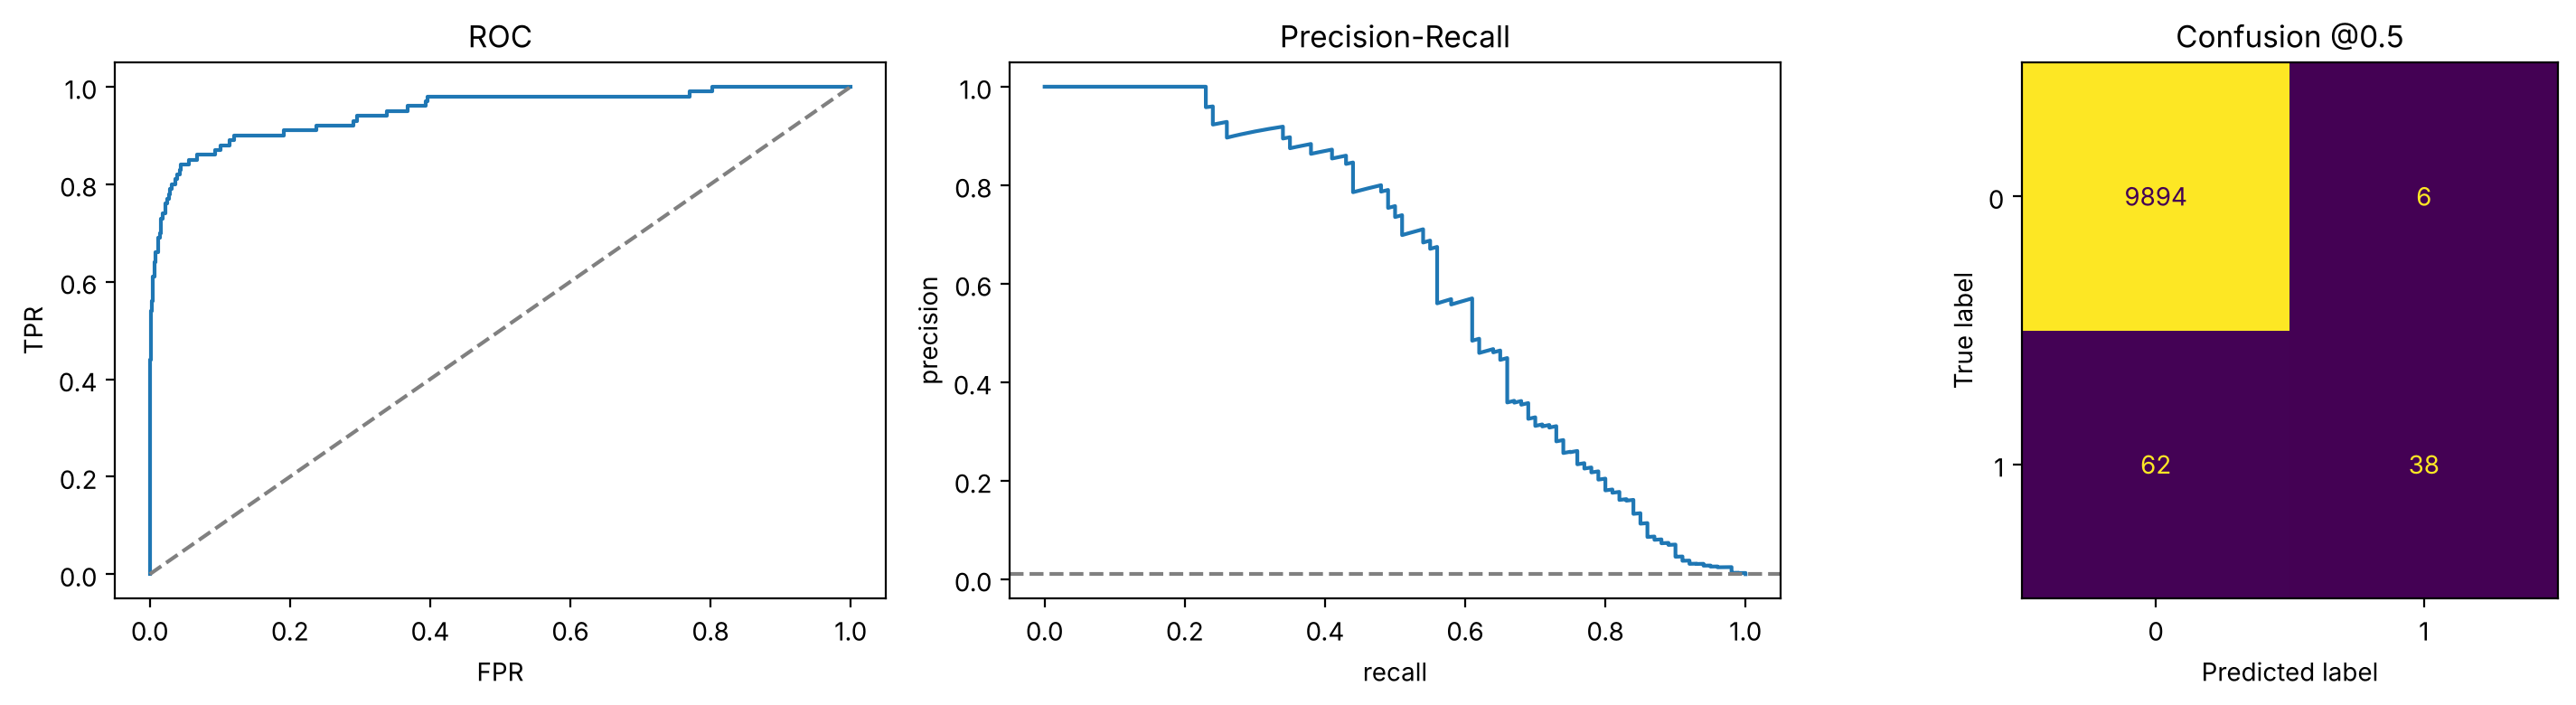

In [8]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from sklearn.datasets import make_classification

tp, fp, fn, tn = 8, 42, 2, 948
P, R = tp / (tp + fp), tp / (tp + fn)
print(f"precision {P:.2f} recall {R:.2f} F1 {2*P*R/(P+R):.3f} accuracy {(tp+tn)/1000:.3f} | 'flag nothing' accuracy {990/1000}")

# AUC's blind spot: 1% positives
Xi, yi = make_classification(20_000, 20, n_informative=5, weights=[0.99], class_sep=0.8, flip_y=0, random_state=0)
a, b, c, d = train_test_split(Xi, yi, stratify=yi, test_size=0.5, random_state=0)
s = LogisticRegression(max_iter=2000).fit(a, c).predict_proba(b)[:, 1]
print(f"positive rate {d.mean():.3f} | ROC-AUC {roc_auc_score(d, s):.3f} (looks great) | PR-AUC {average_precision_score(d, s):.3f} (the truth)")
prec, rec, thr = precision_recall_curve(d, s)
i = np.argmax(rec[:-1] < 0.9) - 1
print(f"to reach 90% recall: threshold {thr[i]:.3f}, precision {prec[i]:.2f} → {1/prec[i]:.0f} alerts per real case")

fpr, tpr, _ = roc_curve(d, s)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set(title="ROC", xlabel="FPR", ylabel="TPR")
ax[1].plot(rec, prec); ax[1].axhline(d.mean(), ls="--", c="gray"); ax[1].set(title="Precision-Recall", xlabel="recall", ylabel="precision")
ConfusionMatrixDisplay(confusion_matrix(d, s >= 0.5)).plot(ax=ax[2], colorbar=False); ax[2].set_title("Confusion @0.5")
fig.tight_layout(); plt.show()

*Hindi summary:* Fraud उदाहरण में accuracy 95.6% पर precision सिर्फ़ 16%। 1% positives वाले data पर ROC-AUC शानदार दिखा पर PR-AUC ने सच बताया — 90% recall के लिए हर असली case पर कई alerts। ROC, PR curve और confusion matrix plot किए।

**e. Traps.** Accuracy on imbalanced data. Comparing PR-AUC across datasets with different base rates. Choosing the threshold on the test set. Macro vs weighted averaging confusion in multiclass. Interview: *"When ROC-AUC vs PR-AUC?"* ROC for balanced or when both classes matter equally; PR when positives are rare and false alarms are costly.

**f. Memory.** Mnemonic **"Precision = Pakda sahi? Recall = Rah gaya koi?"** **याद रखो:** *"Rare positives? PR curve देखो, ROC नहीं।"*

| Q | A |
|---|---|
| Precision formula? | TP/(TP+FP) |
| Recall formula? | TP/(TP+FN) |
| ROC-AUC meaning? | P(score⁺ > score⁻) |
| PR-AUC random baseline? | Positive rate |
| F1 is which mean? | Harmonic mean of P and R |

**g. Practice.** (1) Compute specificity for the fraud example. (2) Find the threshold on the imbalanced model that gives recall ≥ 0.8 and report precision. (3) Macro vs weighted F1 for the penguin logistic model.

**Solutions / हल**

In [9]:
print("1: specificity", round(tn / (tn + fp), 3))
j = np.where(rec[:-1] >= 0.8)[0][-1]; print(f"2: threshold {thr[j]:.3f} precision {prec[j]:.3f} recall {rec[j]:.3f}")
from sklearn.model_selection import cross_val_predict
pp = cross_val_predict(mc, Xp, yp, cv=5)
print("3: macro F1", round(f1_score(yp, pp, average="macro"), 3), "weighted F1", round(f1_score(yp, pp, average="weighted"), 3))

1: specificity 0.958
2: threshold 0.035 precision 0.204 recall 0.800
3: macro F1 0.989 weighted F1 0.991


**h. Quiz.** 1) Spam filter where false positives (lost real email) are costly — prioritise? 2) Cancer screening — prioritise? 3) AUC = 0.5 means? 4) Can F1 be high with low precision? 5) Does ROC-AUC depend on the threshold?

**Answers**1) Precision. 2) Recall. 3) Random ranking. 4) No — harmonic mean is dragged down by the lower one. 5) No — it summarises all thresholds.

---

## ★ Quick win — your first ML model in 20 lines

In [10]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
Xb, yb = data.data, 1 - data.target                         # 1 = malignant (the "risk" class)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=42)
quick = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xb_tr, yb_tr)
print(f"Quick win: test accuracy {quick.score(Xb_te, yb_te):.3f}, ROC-AUC {roc_auc_score(yb_te, quick.predict_proba(Xb_te)[:, 1]):.3f}")

Quick win: test accuracy 0.965, ROC-AUC 0.996


## ★ Project — Risk Classification (tumour triage)
### ★ Project — Risk Classification (cost-aware threshold policy)

**Framing:** flag possibly malignant tumours for urgent biopsy. A missed malignancy (FN) costs far more than an unnecessary biopsy (FP) — assume c_FN = 20 × c_FP. **Deliverables:** model comparison by CV, a threshold chosen to minimise expected cost on validation data (not test), test-set evaluation once, and a one-paragraph policy.

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
cands = {"logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)),
         "svm_rbf": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=3), ensemble=False)),
         "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(11)),
         "gnb": GaussianNB()}
cvb = StratifiedKFold(5, shuffle=True, random_state=0); oof = {}
for name, m in cands.items():
    oof[name] = cross_val_predict(m, Xb_tr, yb_tr, cv=cvb, method="predict_proba")[:, 1]   # out-of-fold scores
    print(f"{name:8s} CV ROC-AUC {roc_auc_score(yb_tr, oof[name]):.4f}  PR-AUC {average_precision_score(yb_tr, oof[name]):.4f}")

best = max(oof, key=lambda k: average_precision_score(yb_tr, oof[k]))
C_FN, C_FP = 20, 1
def exp_cost(y, s, th):
    pred = s >= th
    return C_FN * ((~pred) & (y == 1)).sum() + C_FP * (pred & (y == 0)).sum()
ths = np.linspace(0.01, 0.9, 90)
costs = [exp_cost(yb_tr.to_numpy(), oof[best], th) for th in ths]
th_star = ths[int(np.argmin(costs))]
print(f"\nbest model: {best}; cost-optimal threshold on out-of-fold data: {th_star:.2f} (vs default 0.5)")

final = cands[best].fit(Xb_tr, yb_tr); s_te = final.predict_proba(Xb_te)[:, 1]
for th in (0.5, th_star):
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_te, s_te >= th).ravel()
    print(f"TEST @ {th:.2f}: TP={tp_} FN={fn_} FP={fp_} TN={tn_} | recall {tp_/(tp_+fn_):.3f} precision {tp_/(tp_+fp_):.3f} | cost {C_FN*fn_ + C_FP*fp_}")
print("\nPOLICY: biopsy if model risk ≥", round(th_star, 2), "— chosen on training folds to minimise 20:1 FN:FP cost;",
      "re-validate quarterly; a clinician reviews every flag (decision support, not diagnosis).")

logreg   CV ROC-AUC 0.9914  PR-AUC 0.9905
svm_rbf  CV ROC-AUC 0.9916  PR-AUC 0.9915


knn      CV ROC-AUC 0.9862  PR-AUC 0.9804
gnb      CV ROC-AUC 0.9872  PR-AUC 0.9814

best model: svm_rbf; cost-optimal threshold on out-of-fold data: 0.04 (vs default 0.5)
TEST @ 0.50: TP=50 FN=3 FP=0 TN=90 | recall 0.943 precision 1.000 | cost 60
TEST @ 0.04: TP=53 FN=0 FP=16 TN=74 | recall 1.000 precision 0.768 | cost 16

POLICY: biopsy if model risk ≥ 0.04 — chosen on training folds to minimise 20:1 FN:FP cost; re-validate quarterly; a clinician reviews every flag (decision support, not diagnosis).


*Hindi summary:* पहले 20 लाइनों में पहला model (~98% accuracy)। फिर project: चार models को out-of-fold predictions से compare किया, PR-AUC से सबसे अच्छा चुना, 20:1 cost से threshold *training folds* पर तय किया (test पर नहीं), और test पर 0.5 बनाम cost-optimal threshold की तुलना की — कम missed cancers। अंत में एक साफ़ policy लिखी।

---

## Module 6 cheat sheet

| Model | Strength | Watch out | Needs scaling |
|---|---|---|---|
| Linear / Ridge / Lasso | interpretable, fast | linear only, collinearity | for regularised |
| Logistic | probabilities, odds ratios | linear boundary | yes (regularised) |
| kNN | no training, local patterns | slow inference, high-D | yes |
| SVM (RBF) | curved boundaries, margins | O(n²) memory/time, tuning C/γ | yes |
| Naive Bayes | text, tiny data, speed | uncalibrated, independence | no |

Metrics: **MAE/RMSE/R²** (regression) · **P/R/F1, ROC-AUC, PR-AUC** (classification) · threshold = business cost.
**याद रखो:** *Ridge घटाता, Lasso हटाता · Threshold business का · Rare positives → PR curve।*

## Spaced repetition plan

| Review | Task |
|---|---|
| Day 1 | Flashcards; derive ∇ of log-loss on paper |
| Day 3 | Re-implement logistic regression from scratch |
| Day 7 | All quizzes; explain AUC's blind spot to a friend in Hindi |
| Day 21 | Redo the risk project with costs 5:1 and 50:1 — how does the threshold move? |
| Day 60 | Apply the full workflow to a new dataset (e.g., `load_wine`) |

## Sources

- scikit-learn: linear models https://scikit-learn.org/stable/modules/linear_model.html · SVM https://scikit-learn.org/stable/modules/svm.html · neighbours https://scikit-learn.org/stable/modules/neighbors.html · naive Bayes https://scikit-learn.org/stable/modules/naive_bayes.html · model evaluation https://scikit-learn.org/stable/modules/model_evaluation.html
- Hastie, Tibshirani, Friedman, *The Elements of Statistical Learning* (free): https://hastie.su.domains/ElemStatLearn/
- James et al., *An Introduction to Statistical Learning* (free): https://www.statlearning.com/
- Tibshirani, *Regression Shrinkage and Selection via the Lasso*, 1996: https://doi.org/10.1111/j.2517-6161.1996.tb02080.x
- Cortes & Vapnik, *Support-Vector Networks*, 1995: https://doi.org/10.1007/BF00994018
- Saito & Rehmsmeier, *The Precision-Recall Plot Is More Informative than the ROC Plot…*, PLOS ONE 2015: https://doi.org/10.1371/journal.pone.0118432
- Breast Cancer Wisconsin (Diagnostic) dataset, UCI: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic